This notebook contains exploration of Vietnam government statistics offce data.

In [31]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings

# Suppress all warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv("../data/cleaned_gso.csv")

In [4]:
df.head()

,province_name,macro_region,year,season,planted_area_ha,production_tons,yield_ton_ha
0,An Giang,Mekong River Delta,2005,autumn,298.1,1568.7,5.26
1,An Giang,Mekong River Delta,2005,spring,229.4,1547.6,6.93
2,An Giang,Mekong River Delta,2005,winter,8.3,25.3,3.05
3,An Giang,Mekong River Delta,2006,autumn,265.1,1327.0,5.01
4,An Giang,Mekong River Delta,2006,spring,229.4,1572.7,6.81


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3117 entries, 0 to 3116
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   province_name    3117 non-null   str    
 1   macro_region     3117 non-null   str    
 2   year             3117 non-null   int64  
 3   season           3117 non-null   str    
 4   planted_area_ha  3117 non-null   float64
 5   production_tons  3117 non-null   float64
 6   yield_ton_ha     3117 non-null   float64
dtypes: float64(3), int64(1), str(3)
memory usage: 292.4 KB


In [10]:
df["province_name"].nunique()

63

In [11]:
df["macro_region"].nunique()

6

In [17]:
print(df["year"].nunique())
print(df["year"].unique())

21
[2005 2006 2007 2008 2009 2010 2011 2012 2013 2014 2015 2016 2017 2018
 2019 2020 2021 2022 2023 2024 2025]


In [19]:
# Group by Year to get national annual totals
df_national = df.groupby('year').agg(
    total_planted_area_ha=('planted_area_ha', 'sum'),
    total_production_tons=('production_tons', 'sum')
).reset_index()

# Recalculate true national yield (Production / Area)
df_national['national_yield_ton_ha'] = (
    df_national['total_production_tons'] / df_national['total_planted_area_ha']
).round(2)

df_national

,year,total_planted_area_ha,total_production_tons,national_yield_ton_ha
0,2005,7355.6,35505.3,4.83
1,2006,7298.8,35531.3,4.87
2,2007,7152.7,35611.7,4.98
3,2008,7343.3,38569.2,5.25
4,2009,7331.4,38790.9,5.29
5,2010,7359.3,39850.8,5.42
6,2011,7515.1,42229.1,5.62
7,2012,7593.1,43571.0,5.74
8,2013,7753.1,43888.0,5.66
9,2014,7655.7,44798.6,5.85


In [23]:
# Aggregate 3 seasons into 1 annual row per province and year
df_annual = df.groupby(['macro_region']).agg(
    annual_planted_area_ha=('planted_area_ha', 'sum'),
    annual_production_tons=('production_tons', 'sum')
).reset_index()

# Compute annual weighted yield
df_annual['annual_yield_ton_ha'] = (
    df_annual['annual_production_tons'] / df_annual['annual_planted_area_ha']
).round(2)

df_annual.head()

,macro_region,annual_planted_area_ha,annual_production_tons,annual_yield_ton_ha
0,Central Highlands,5082.4,25614.3,5.04
1,Mekong River Delta,83388.3,483534.3,5.80
2,North Central and Central coastal areas,24790.6,136212.5,5.49
3,Northern midlands and mountain areas,14082.0,67850.3,4.82
4,Red River Delta,21573.1,133199.0,6.17


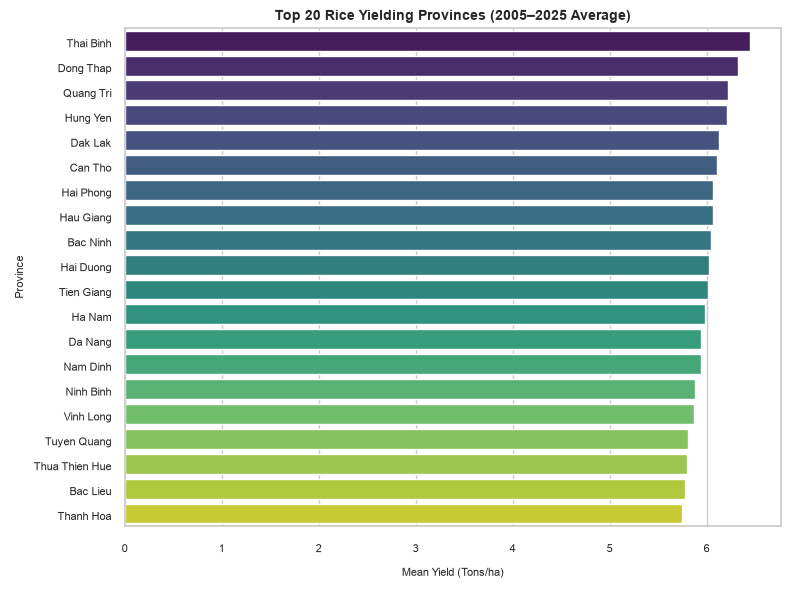

In [32]:
plt.figure(figsize=(8, 6))

# Rank top 20 provinces by historical average yield
province_rank = df.groupby("province_name")["yield_ton_ha"].mean().sort_values(ascending=False).head(20).reset_index()

# Set base font size for seaborn elements
sns.set_theme(style="whitegrid", font_scale=0.8)

ax = sns.barplot(
    data=province_rank,
    x="yield_ton_ha",
    y="province_name",
    palette="viridis"
)

# Customizing individual text elements and font sizes
plt.title("Top 20 Rice Yielding Provinces (2005–2025 Average)", fontsize=10, fontweight="bold")
plt.xlabel("Mean Yield (Tons/ha)", fontsize=8)
plt.ylabel("Province", fontsize=8)

# Adjust axis tick label sizes (province names and yield numbers)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)

plt.tight_layout()
plt.show()

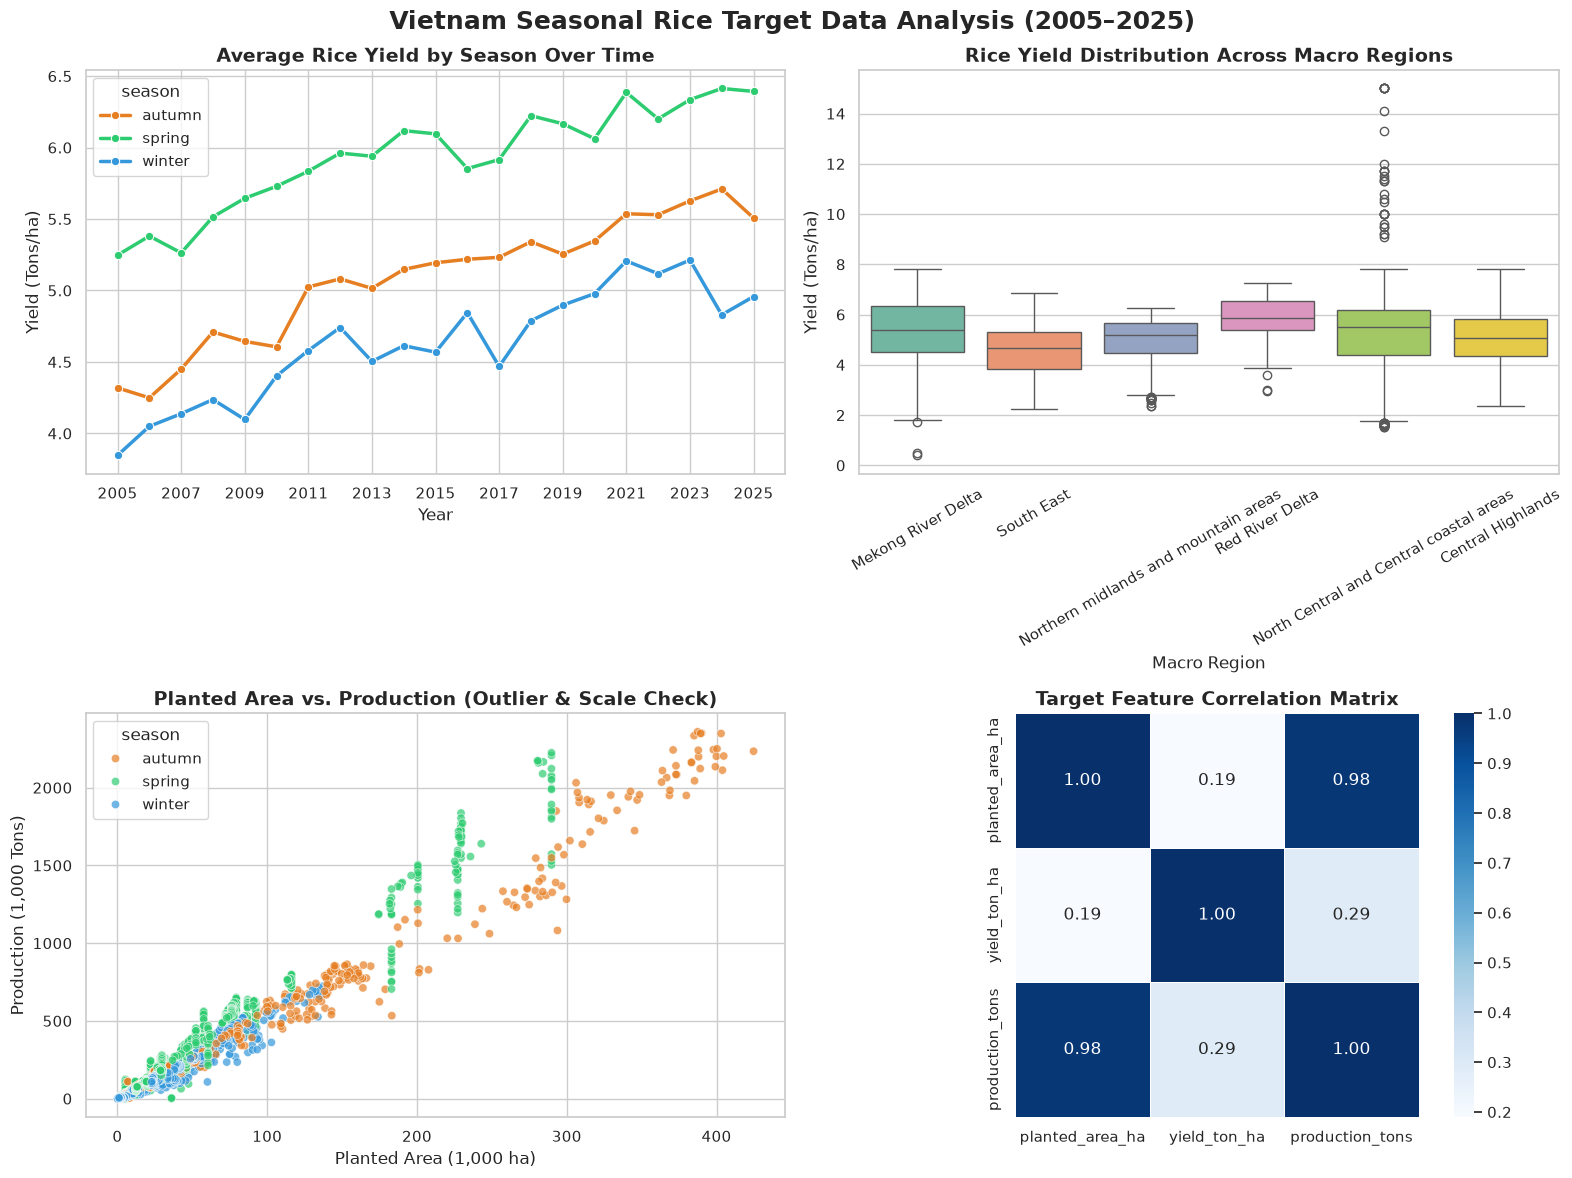

In [33]:
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Vietnam Seasonal Rice Target Data Analysis (2005–2025)", fontsize=18, fontweight="bold")

# -------------------------------------------------------------------------
# Plot 1: National Mean Rice Yield Trend by Season
# -------------------------------------------------------------------------
seasonal_yield = df.groupby(["year", "season"])["yield_ton_ha"].mean().reset_index()

sns.lineplot(
    data=seasonal_yield,
    x="year",
    y="yield_ton_ha",
    hue="season",
    marker="o",
    linewidth=2.5,
    palette={"spring": "#2ecc71", "autumn": "#e67e22", "winter": "#3498db"},
    ax=axes[0, 0]
)
axes[0, 0].set_title("Average Rice Yield by Season Over Time", fontsize=14, fontweight="bold")
axes[0, 0].set_xlabel("Year")
axes[0, 0].set_ylabel("Yield (Tons/ha)")
axes[0, 0].set_xticks(range(2005, 2026, 2))

# -------------------------------------------------------------------------
# Plot 2: Yield Distribution Across Top Macro Regions
# -------------------------------------------------------------------------
sns.boxplot(
    data=df,
    x="macro_region",
    y="yield_ton_ha",
    palette="Set2",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Rice Yield Distribution Across Macro Regions", fontsize=14, fontweight="bold")
axes[0, 1].set_xlabel("Macro Region")
axes[0, 1].set_ylabel("Yield (Tons/ha)")
axes[0, 1].tick_params(axis="x", rotation=30)

# -------------------------------------------------------------------------
# Plot 3: Planted Area vs. Production Relationship
# -------------------------------------------------------------------------
sns.scatterplot(
    data=df,
    x="planted_area_ha",
    y="production_tons",
    hue="season",
    alpha=0.7,
    palette={"spring": "#2ecc71", "autumn": "#e67e22", "winter": "#3498db"},
    ax=axes[1, 0]
)
axes[1, 0].set_title("Planted Area vs. Production (Outlier & Scale Check)", fontsize=14, fontweight="bold")
axes[1, 0].set_xlabel("Planted Area (1,000 ha)")
axes[1, 0].set_ylabel("Production (1,000 Tons)")

# -------------------------------------------------------------------------
# Plot 4: Target Metrics Correlation Heatmap
# -------------------------------------------------------------------------
corr = df[["planted_area_ha", "yield_ton_ha", "production_tons"]].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    cbar=True,
    square=True,
    linewidths=0.5,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Target Feature Correlation Matrix", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()